# `scripts/data_overview.py`

報告 `report/expected_score.typ` 的「資料與樣本」：各速度類別的局數、arena 局數、2014 年玩家數。

本 notebook 由 `notebooks/build.py` 從腳本自動產生，內容以腳本為準。

第一份報告（資料介紹）的描述統計：規模、組成、缺失、配對來源與分差分布。
只做分組計數與分布，不做任何檢定或模型。
前瞻驗證期（2015-01-01 至 2015-04-19 的 arena）只算局數、玩家數、錦標賽數；
結果與續下在驗證前不得看，故 2014 年以外的對局一律只計數。

In [1]:
import gzip
import json

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

In [3]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
HOLDOUT_END = pl.datetime(2015, 4, 20, time_zone="UTC")

In [4]:
games = pl.scan_parquet("data/processed/lichess_games.parquet")

In [5]:
src = []
with gzip.open("data/raw/lichess-game-meta/games.ndjson.gz", "rt") as f:
    for l in f:
        d = json.loads(l)
        src.append((d["id"], d.get("source")))
src = pl.DataFrame(src, schema=["game_id", "source"], orient="row").with_columns(queried=pl.lit(True)).lazy()

In [6]:
g14 = (
    games.filter(pl.col("start").dt.year() == 2014)
    .join(src, on="game_id", how="left")
    .with_columns(arena=pl.col("tournament_id").is_not_null(), queried=pl.col("queried").fill_null(False))
    .collect()
)

各月局數。月份依 UTC 開局時間，不依月檔（月檔依法國當地時間切分）

In [7]:
monthly = (
    games.group_by(month=pl.col("start").dt.truncate("1mo"), arena=pl.col("tournament_id").is_not_null())
    .len()
    .collect()
    .pivot(on="arena", index="month", values="len")
    .rename({"true": "arena", "false": "other"})
    .fill_null(0)
    .sort("month")
)
print(monthly)
monthly.write_csv("outputs/tables/data_overview_monthly.csv")

shape: (31, 3)
┌─────────────────────────┬────────┬─────────┐
│ month                   ┆ arena  ┆ other   │
│ ---                     ┆ ---    ┆ ---     │
│ datetime[μs, UTC]       ┆ u32    ┆ u32     │
╞═════════════════════════╪════════╪═════════╡
│ 2012-12-01 00:00:00 UTC ┆ 0      ┆ 135     │
│ 2013-01-01 00:00:00 UTC ┆ 1215   ┆ 120148  │
│ 2013-02-01 00:00:00 UTC ┆ 1623   ┆ 122399  │
│ 2013-03-01 00:00:00 UTC ┆ 2013   ┆ 156756  │
│ 2013-04-01 00:00:00 UTC ┆ 3416   ┆ 154538  │
│ …                       ┆ …      ┆ …       │
│ 2015-02-01 00:00:00 UTC ┆ 213312 ┆ 1282385 │
│ 2015-03-01 00:00:00 UTC ┆ 250482 ┆ 1494806 │
│ 2015-04-01 00:00:00 UTC ┆ 254121 ┆ 1531379 │
│ 2015-05-01 00:00:00 UTC ┆ 366147 ┆ 1772789 │
│ 2015-06-01 00:00:00 UTC ┆ 463753 ┆ 1854175 │
└─────────────────────────┴────────┴─────────┘


In [8]:
holdout = (
    games.filter(pl.col("tournament_id").is_not_null(), pl.col("start").dt.year() == 2015, pl.col("start") < HOLDOUT_END)
    .select(
        games=pl.len(),
        players=pl.concat_list("white_id", "black_id").explode().n_unique(),
        tournaments=pl.col("tournament_id").n_unique(),
    )
    .collect()
)
print(holdout)
holdout.write_csv("outputs/tables/data_overview_holdout.csv")

/tmp/ipykernel_3356599/3131156302.py:5: DeprecationWarning: In Polars 2.0, the default behavior for `empty_as_null` will change to `False`. To keep the current behavior, explicitly set `empty_as_null=True`.
  players=pl.concat_list("white_id", "black_id").explode().n_unique(),


shape: (1, 3)
┌────────┬─────────┬─────────────┐
│ games  ┆ players ┆ tournaments │
│ ---    ┆ ---     ┆ ---         │
│ u32    ┆ u32     ┆ u32         │
╞════════╪═════════╪═════════════╡
│ 842016 ┆ 21914   ┆ 7305        │
└────────┴─────────┴─────────────┘


In [9]:
scale = (
    games.group_by(year=pl.col("start").dt.year())
    .agg(
        games=pl.len(),
        players=pl.concat_list("white_id", "black_id").explode().n_unique(),
        arena_games=pl.col("tournament_id").is_not_null().sum(),
        tournaments=pl.col("tournament_id").n_unique() - 1,
    )
    .sort("year")
    .collect()
)
print(scale)
scale.write_csv("outputs/tables/data_overview_scale.csv")

/tmp/ipykernel_3356599/1661795851.py:5: DeprecationWarning: In Polars 2.0, the default behavior for `empty_as_null` will change to `False`. To keep the current behavior, explicitly set `empty_as_null=True`.
  players=pl.concat_list("white_id", "black_id").explode().n_unique(),


shape: (4, 5)
┌──────┬──────────┬─────────┬─────────────┬─────────────┐
│ year ┆ games    ┆ players ┆ arena_games ┆ tournaments │
│ ---  ┆ ---      ┆ ---     ┆ ---         ┆ ---         │
│ i32  ┆ u32      ┆ u32     ┆ u32         ┆ u32         │
╞══════╪══════════╪═════════╪═════════════╪═════════════╡
│ 2012 ┆ 135      ┆ 83      ┆ 0           ┆ 0           │
│ 2013 ┆ 3386925  ┆ 73600   ┆ 73014       ┆ 8378        │
│ 2014 ┆ 11596047 ┆ 184919  ┆ 998790      ┆ 21942       │
│ 2015 ┆ 10981351 ┆ 163944  ┆ 1765035     ┆ 13391       │
└──────┴──────────┴─────────┴─────────────┴─────────────┘


In [10]:
missing = g14.select(
    games=pl.len(),
    elo_missing=(pl.col("white_elo").is_null() | pl.col("black_elo").is_null()).sum(),
    rating_diff_missing=pl.col("white_rating_diff").is_null().sum(),
    unfinished=(pl.col("result") == "*").sum(),
    not_queried=(~pl.col("queried")).sum(),
    source_missing=(pl.col("queried") & pl.col("source").is_null()).sum(),
)
print(missing)
missing.write_csv("outputs/tables/data_overview_missing.csv")

shape: (1, 6)
┌──────────┬─────────────┬─────────────────────┬────────────┬─────────────┬────────────────┐
│ games    ┆ elo_missing ┆ rating_diff_missing ┆ unfinished ┆ not_queried ┆ source_missing │
│ ---      ┆ ---         ┆ ---                 ┆ ---        ┆ ---         ┆ ---            │
│ u32      ┆ u32         ┆ u32                 ┆ u32        ┆ u32         ┆ u32            │
╞══════════╪═════════════╪═════════════════════╪════════════╪═════════════╪════════════════╡
│ 11596047 ┆ 885         ┆ 68088               ┆ 101        ┆ 3           ┆ 231320         │
└──────────┴─────────────┴─────────────────────┴────────────┴─────────────┴────────────────┘


全年：錦標賽由 Event 即可分出；一般對局的大廳、邀戰、無 source 只在已查詢者分得出

In [11]:
source = (
    g14.select(
        kind=pl.when("arena").then(pl.lit("arena")).when(~pl.col("queried")).then(pl.lit("not queried yet")).otherwise(pl.col("source").fill_null("no source"))
    )
    .group_by("kind")
    .len()
    .sort("len", descending=True)
)
print(source)
source.write_csv("outputs/tables/data_overview_source.csv")

shape: (5, 2)
┌─────────────────┬──────────┐
│ kind            ┆ len      │
│ ---             ┆ ---      │
│ str             ┆ u32      │
╞═════════════════╪══════════╡
│ lobby           ┆ 10234089 │
│ arena           ┆ 998790   │
│ no source       ┆ 231320   │
│ friend          ┆ 131845   │
│ not queried yet ┆ 3        │
└─────────────────┴──────────┘


In [12]:
speed = g14.group_by("arena", "speed").len().sort("arena", "speed")
print(speed)
speed.write_csv("outputs/tables/data_overview_speed.csv")

shape: (7, 3)
┌───────┬────────────────┬─────────┐
│ arena ┆ speed          ┆ len     │
│ ---   ┆ ---            ┆ ---     │
│ bool  ┆ str            ┆ u32     │
╞═══════╪════════════════╪═════════╡
│ false ┆ Blitz          ┆ 4391895 │
│ false ┆ Bullet         ┆ 3025927 │
│ false ┆ Classical      ┆ 3172932 │
│ false ┆ Correspondence ┆ 6503    │
│ true  ┆ Blitz          ┆ 554018  │
│ true  ┆ Bullet         ┆ 411037  │
│ true  ┆ Classical      ┆ 33735   │
└───────┴────────────────┴─────────┘


In [13]:
result = g14.filter(pl.col("result") != "*").group_by("speed", "result").len().sort("speed", "result")
print(result)
result.write_csv("outputs/tables/data_overview_result.csv")

shape: (12, 3)
┌────────────────┬─────────┬─────────┐
│ speed          ┆ result  ┆ len     │
│ ---            ┆ ---     ┆ ---     │
│ str            ┆ str     ┆ u32     │
╞════════════════╪═════════╪═════════╡
│ Blitz          ┆ 0-1     ┆ 2274606 │
│ Blitz          ┆ 1-0     ┆ 2480320 │
│ Blitz          ┆ 1/2-1/2 ┆ 190987  │
│ Bullet         ┆ 0-1     ┆ 1607154 │
│ Bullet         ┆ 1-0     ┆ 1734650 │
│ …              ┆ …       ┆ …       │
│ Classical      ┆ 1-0     ┆ 1611852 │
│ Classical      ┆ 1/2-1/2 ┆ 127497  │
│ Correspondence ┆ 0-1     ┆ 2923    │
│ Correspondence ┆ 1-0     ┆ 3189    │
│ Correspondence ┆ 1/2-1/2 ┆ 391     │
└────────────────┴─────────┴─────────┘


依分差分組的勝和負比例，與期望得分曲線對照。分差取白方減黑方，50 分一組；
600 分以外的對局少，不畫。只做比例，不擬合任何模型。pool 試行的 6 至 10 月
表頭是 pool 自己的等級分，尺度不同，比照分差分布排除

In [14]:
by_gap = (
    g14.filter(
        pl.col("result") != "*",
        pl.col("white_elo").is_not_null(),
        pl.col("black_elo").is_not_null(),
        ~pl.col("start").dt.month().is_between(6, 10),
    )
    .with_columns(d=((pl.col("white_elo") - pl.col("black_elo")) / 50).round() * 50)
    .filter(pl.col("d").abs() <= 600)
    .group_by("d", "result")
    .len()
    .sort("d", "result")
)
print(by_gap)
by_gap.write_csv("outputs/tables/data_overview_result_by_gap.csv")

shape: (75, 3)
┌────────┬─────────┬───────┐
│ d      ┆ result  ┆ len   │
│ ---    ┆ ---     ┆ ---   │
│ f64    ┆ str     ┆ u32   │
╞════════╪═════════╪═══════╡
│ -600.0 ┆ 0-1     ┆ 12934 │
│ -600.0 ┆ 1-0     ┆ 1116  │
│ -600.0 ┆ 1/2-1/2 ┆ 177   │
│ -550.0 ┆ 0-1     ┆ 18123 │
│ -550.0 ┆ 1-0     ┆ 1764  │
│ …      ┆ …       ┆ …     │
│ 550.0  ┆ 1-0     ┆ 20644 │
│ 550.0  ┆ 1/2-1/2 ┆ 265   │
│ 600.0  ┆ 0-1     ┆ 1033  │
│ 600.0  ┆ 1-0     ┆ 14970 │
│ 600.0  ┆ 1/2-1/2 ┆ 133   │
└────────┴─────────┴───────┘


In [15]:
per_player = (
    pl.concat([g14.select("arena", p=pl.col("white_id")), g14.select("arena", p=pl.col("black_id"))])
    .group_by("p")
    .agg(games=pl.len(), arena_games=pl.col("arena").sum())
)
pp_summary = per_player.select(
    players=pl.len(),
    arena_players=(pl.col("arena_games") > 0).sum(),
    **{f"q{int(q * 100)}": pl.col("games").quantile(q) for q in [0.25, 0.5, 0.75, 0.9, 0.99]},
    max=pl.col("games").max(),
)
print(pp_summary)
pp_summary.write_csv("outputs/tables/data_overview_per_player.csv")

shape: (1, 8)
┌─────────┬───────────────┬─────┬─────┬──────┬───────┬────────┬───────┐
│ players ┆ arena_players ┆ q25 ┆ q50 ┆ q75  ┆ q90   ┆ q99    ┆ max   │
│ ---     ┆ ---           ┆ --- ┆ --- ┆ ---  ┆ ---   ┆ ---    ┆ ---   │
│ u32     ┆ u32           ┆ f64 ┆ f64 ┆ f64  ┆ f64   ┆ f64    ┆ u32   │
╞═════════╪═══════════════╪═════╪═════╪══════╪═══════╪════════╪═══════╡
│ 184919  ┆ 30082         ┆ 2.0 ┆ 5.0 ┆ 28.0 ┆ 200.0 ┆ 2425.0 ┆ 31362 │
└─────────┴───────────────┴─────┴─────┴──────┴───────┴────────┴───────┘


大廳以全部非錦標賽對局代理：source 尚未查完，已查部分中邀戰只佔一般對局約 1%，
不改變分布形狀。pool 試行的 6 至 10 月兩邊都排除，pool 的配對另有規則

In [16]:
gap = g14.filter(~pl.col("start").dt.month().is_between(6, 10), pl.col("white_elo").is_not_null(), pl.col("black_elo").is_not_null()).select(
    "arena", gap=(pl.col("white_elo") - pl.col("black_elo")).abs()
)
gap_summary = gap.group_by("arena").agg(n=pl.len(), **{f"q{int(q * 100)}": pl.col("gap").quantile(q) for q in [0.25, 0.5, 0.75, 0.9]}).sort("arena")
print(gap_summary)
gap_summary.write_csv("outputs/tables/data_overview_rating_gap.csv")

shape: (2, 6)
┌───────┬─────────┬───────┬───────┬───────┬───────┐
│ arena ┆ n       ┆ q25   ┆ q50   ┆ q75   ┆ q90   │
│ ---   ┆ ---     ┆ ---   ┆ ---   ┆ ---   ┆ ---   │
│ bool  ┆ u32     ┆ f64   ┆ f64   ┆ f64   ┆ f64   │
╞═══════╪═════════╪═══════╪═══════╪═══════╪═══════╡
│ false ┆ 5963920 ┆ 45.0  ┆ 101.0 ┆ 187.0 ┆ 296.0 │
│ true  ┆ 497430  ┆ 103.0 ┆ 222.0 ┆ 385.0 ┆ 557.0 │
└───────┴─────────┴───────┴───────┴───────┴───────┘


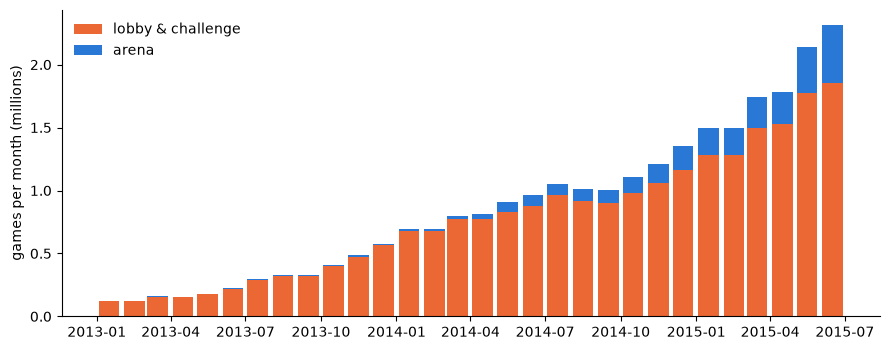

In [17]:
fig, ax = plt.subplots(figsize=(9, 3.6))
# 2012-12 的少數對局是月檔依法國時間切分留下的，不畫
mp = monthly.filter(pl.col("month").dt.year() >= 2013)
m = mp["month"].dt.replace_time_zone(None).to_numpy() + np.timedelta64(15, "D")
other, arena = mp["other"].to_numpy() / 1e6, mp["arena"].to_numpy() / 1e6
ax.bar(m, other, width=np.timedelta64(25, "D"), color=ORANGE, label="lobby & challenge")
ax.bar(m, arena, width=np.timedelta64(25, "D"), bottom=other, color=BLUE, label="arena")
ax.set_ylabel("games per month (millions)")
ax.legend(loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/figures/data_overview_timeline.svg")

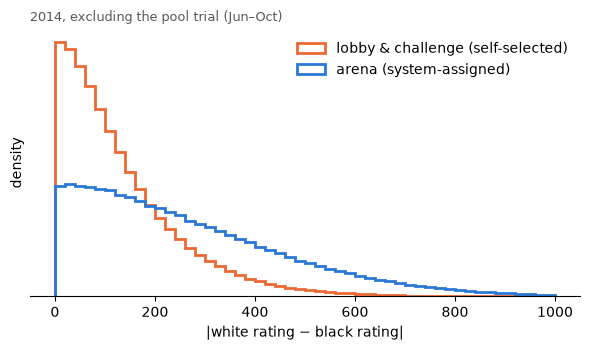

In [18]:
fig, ax = plt.subplots(figsize=(6, 3.6))
bins = np.arange(0, 1001, 20)
for arena, c, lab in [(False, ORANGE, "lobby & challenge (self-selected)"), (True, BLUE, "arena (system-assigned)")]:
    x = gap.filter(pl.col("arena") == arena)["gap"].to_numpy()
    ax.hist(x, bins=bins, density=True, histtype="step", lw=2, color=c, label=lab)
ax.set_xlabel("|white rating − black rating|")
ax.set_title("2014, excluding the pool trial (Jun–Oct)", fontsize=9, loc="left", color="0.35")
ax.set_ylabel("density")
ax.set_yticks([])
ax.legend(frameon=False)
ax.spines[["top", "right", "left"]].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/figures/data_overview_rating_gap.svg")

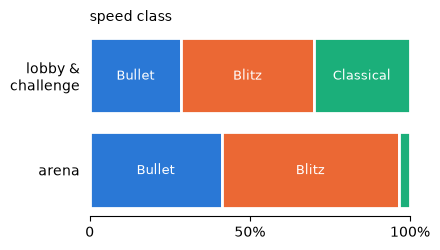

In [19]:
order = ["Bullet", "Blitz", "Classical"]
fig, ax = plt.subplots(figsize=(4.5, 2.6))
for i, arena in enumerate([True, False]):
    s_ = speed.filter(pl.col("arena") == arena)
    tot = s_["len"].sum()
    left = 0
    for sp, c in zip(order, [BLUE, ORANGE, AQUA]):
        v = s_.filter(pl.col("speed") == sp)["len"].sum() / tot
        ax.barh(i, v, left=left, color=c, edgecolor="white", lw=2)
        if v > 0.06:
            ax.text(left + v / 2, i, sp, ha="center", va="center", color="white", fontsize=9)
        left += v
ax.set_yticks([0, 1], ["arena", "lobby &\nchallenge"])
ax.set_xlim(0, 1)
ax.set_xticks([0, 0.5, 1], ["0", "50%", "100%"])
ax.set_title("speed class", fontsize=10, loc="left")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(left=False)
fig.tight_layout()
fig.savefig("outputs/figures/data_overview_composition.svg")

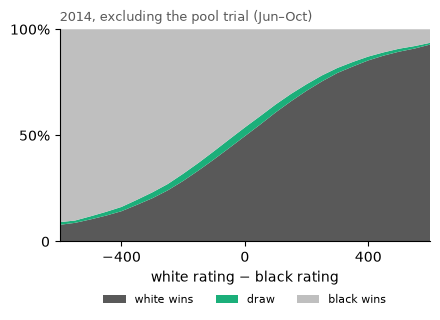

In [20]:
wide = by_gap.pivot(on="result", index="d", values="len").fill_null(0).sort("d")
d = wide["d"].to_numpy()
n = wide.select(pl.sum_horizontal("1-0", "1/2-1/2", "0-1")).to_series().to_numpy()
fig, ax = plt.subplots(figsize=(4.5, 3.4))
ax.stackplot(
    d,
    wide["1-0"].to_numpy() / n,
    wide["1/2-1/2"].to_numpy() / n,
    wide["0-1"].to_numpy() / n,
    colors=["0.35", AQUA, "0.75"],
    labels=["white wins", "draw", "black wins"],
)
ax.set_xlim(-600, 600)
ax.set_ylim(0, 1)
ax.set_xticks([-400, 0, 400])
ax.set_yticks([0, 0.5, 1], ["0", "50%", "100%"])
ax.set_xlabel("white rating − black rating")
ax.set_title("2014, excluding the pool trial (Jun–Oct)", fontsize=9, loc="left", color="0.35")
ax.legend(ncols=3, frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/figures/data_overview_result_by_gap.svg")

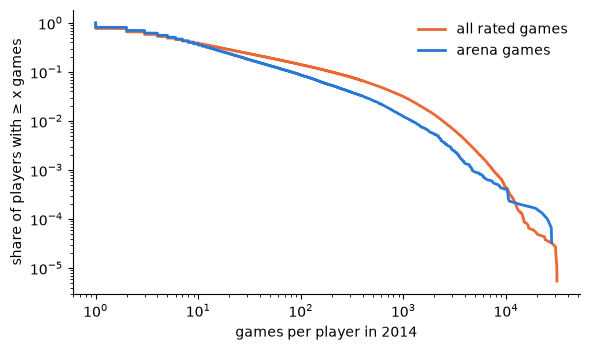

In [21]:
fig, ax = plt.subplots(figsize=(6, 3.6))
for col, c, lab in [("games", ORANGE, "all rated games"), ("arena_games", BLUE, "arena games")]:
    x = np.sort(per_player.filter(pl.col(col) > 0)[col].to_numpy())
    ccdf = 1 - np.arange(len(x)) / len(x)
    ax.loglog(x, ccdf, color=c, lw=2, label=lab)
ax.set_xlabel("games per player in 2014")
ax.set_ylabel("share of players with ≥ x games")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/figures/data_overview_per_player.svg")

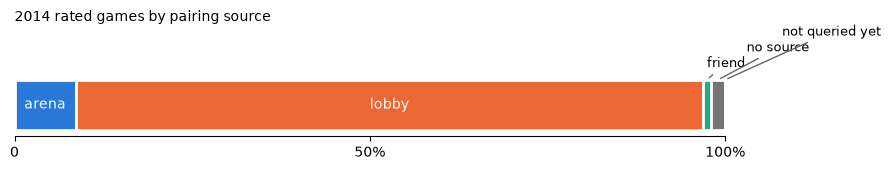

In [22]:
fig, ax = plt.subplots(figsize=(9, 1.8))
tot = source["len"].sum()
left, k = 0, 0
for kind, c in [("arena", BLUE), ("lobby", ORANGE), ("friend", AQUA), ("no source", "0.45"), ("not queried yet", "0.85")]:
    v = source.filter(pl.col("kind") == kind)["len"].sum() / tot
    ax.barh(0, v, left=left, color=c, edgecolor="white", lw=2)
    if v > 0.04:
        ax.text(left + v / 2, 0, kind, ha="center", va="center", color="white" if kind != "not queried yet" else "0.25", fontsize=10)
    elif v > 0:
        # 窄段的標籤錯開高度，免得相鄰的兩段疊字
        ax.annotate(kind, (left + v / 2, 0.4), (left + v / 2 + 0.04 * k, 0.6 + 0.25 * k), ha="left", fontsize=9, arrowprops=dict(arrowstyle="-", color="0.4"))
        k += 1
    left += v
ax.set_xlim(0, 1)
ax.set_ylim(-0.5, 1.2)
ax.set_yticks([])
ax.set_xticks([0, 0.5, 1], ["0", "50%", "100%"])
ax.set_title("2014 rated games by pairing source", fontsize=10, loc="left")
ax.spines[["top", "right", "left"]].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/figures/data_overview_source.svg")